# 02 — Feature engineering and a selected report
**Practical 2: the same 40 applicants, one hidden access barrier.** Slides 39–52. This replaces the former matched-neighbor and validation/re-audit paths with one countable process.

By the end, you can distinguish a recorded fact from an engineered judgment, trace exclusions, detect a misleading denominator and evaluate a concrete rule change. No classifier training or complex neighbor algorithm is needed.

## Part 1 — A complete ethical data-engineering audit
### 1. Read the declared scenario before processing data
The opportunity is an invitation to an **online** Analyst assessment. All 40 complete applicants meet the stated skill cutoff, and there are 40 assessment seats. The scenario assumes the cutoff is job-related; a real deployment would need to validate that assumption and ensure accessibility.

The company defines `ready_for_work=has_car`. It invites only people passing both the skill and car criteria. The car distribution is deliberately constructed to reproduce the 12/20 versus 4/20 denial counts. This is not a real demographic claim.

In [1]:
from pathlib import Path  # Locate the extracted practical pack.
import sys  # Make the small teaching helper module importable.
import numpy as np  # Calculate probabilities and reproducible simulations.
import pandas as pd  # Load and inspect the actual row-level data.
import matplotlib.pyplot as plt  # Draw figures from computed values.
from scipy.stats import norm, fisher_exact  # Use documented reference distributions and tests.
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/audit.py').exists())  # Find the pack from its root or notebooks folder.
sys.path.insert(0, str(root / 'src'))  # Import helpers from this pack, not an unrelated installation.
from audit import wilson, report, rule_metrics, search_contexts, family_false_alarm  # Load inspectable functions.
from prepare_data import prepare  # Reproduce the constructed raw and processed data.
applicants = prepare(root)  # Generate the same deterministic 40-person cohort.
plt.rcParams.update({'font.size': 12, 'figure.dpi': 130})  # Keep notebook figures legible.
print(root, '\nRecords:', len(applicants))  # Verify the active dataset location and size.

/workspace/scratch/a78d3bf087d5/build/discovery-simple/practical 
Records: 40


In [2]:
raw = pd.read_csv(root / 'data/raw/applicants_40.csv')  # Inspect unfiltered source records rather than a published subset.
print(raw.head(8).to_string(index=False))  # Show factual fields before engineered judgments.
assert raw.application_complete.eq(1).all() and raw.skill_score.ge(70).all()  # Verify that all forty meet the stated population definition.
print(pd.crosstab(raw.group, raw.has_car))  # Check the constructed feature distribution directly.

record_id group    role  skill_score  certificate  experience_years  has_car  application_complete
      W01 Women Analyst           77            0                 1        0                     1
      W02 Women Analyst           84            0                 2        0                     1
      W03 Women Analyst           91            0                 1        0                     1
      W04 Women Analyst           98            0                 2        0                     1
      W05 Women Analyst           74            0                 1        1                     1
      W06 Women Analyst           81            0                 3        0                     1
      W07 Women Analyst           88            0                 4        0                     1
      W08 Women Analyst           95            0                 5        0                     1
has_car   0   1
group          
Men       4  16
Women    12   8


### 2. Trace an engineered feature
`has_car` can accurately record car ownership. That does not mean it measures reliability, readiness or ability to take an online assessment. A positive feature name can hide a poor measurement choice.

Here `group` is not in the access formula, yet the feature creates an unequal group burden. A group-correlated feature is not automatically forbidden or invalid; its role, necessity, measurement and available alternatives need contextual review. This particular scenario supplies no travel requirement that would justify the car filter.

In [3]:
engineered = raw.copy()  # Preserve source observations while deriving separate fields.
engineered['meets_minimum'] = engineered.skill_score.ge(70).astype(int)  # Apply the stated minimum criterion.
engineered['ready_for_work'] = engineered.has_car  # Expose the exact questionable feature transformation.
engineered['invited'] = (engineered.meets_minimum.eq(1) & engineered.ready_for_work.eq(1)).astype(int)  # Implement the original access rule.
engineered['denied'] = 1-engineered.invited  # Record the adverse outcome with explicit direction.
print(report(engineered, 'invited').to_string(index=False))  # Calculate favorable rates over all complete applicants.
print(report(engineered, 'denied').to_string(index=False))  # Reconcile the original denial rates from Practical 1.
assert engineered.invited.sum() == 24  # Check that this rule grants access to twenty-four people.

group  events  total  rate
Women       8     20   0.4
  Men      16     20   0.8
group  events  total  rate
Women      12     20   0.6
  Men       4     20   0.2


### 3. Make both process branches visible
All 40 applicants pass the stated skill check. The extra car filter admits 24 and excludes 16. Women: 8 invited, 12 excluded. Men: 16 invited, 4 excluded.

The same rule applied to everyone can still impose different burdens. A statistical disparity alone does not establish a legal conclusion, but the known irrelevant feature in this simulation provides a concrete process issue to review.

invited  Denied  Invited
group                   
Men           4       16
Women        12        8


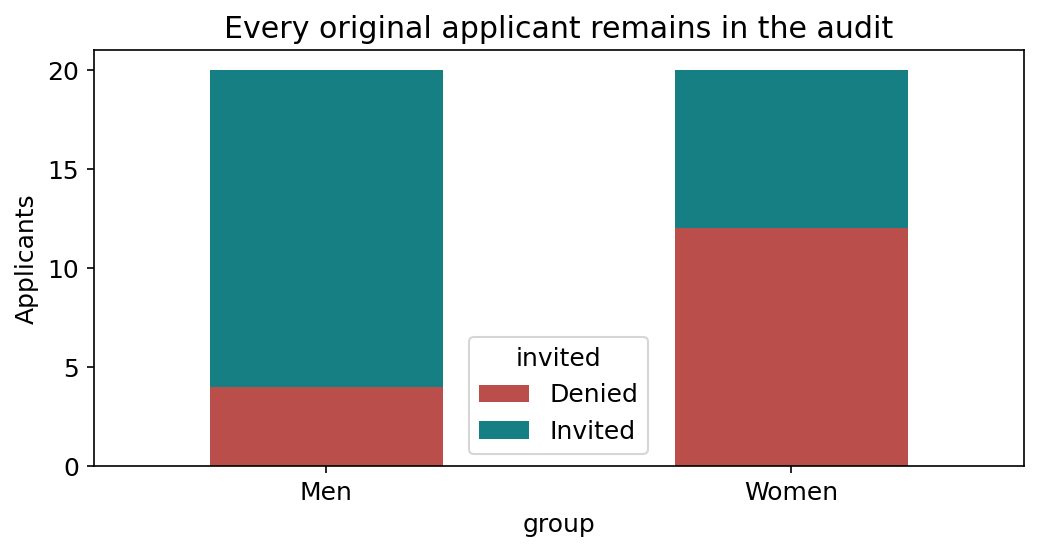

In [4]:
process_counts = pd.crosstab(engineered.group, engineered.invited).rename(columns={0: 'Denied', 1: 'Invited'})  # Retain both branches of the process.
print(process_counts)  # Check the numerators that will appear in the report.
fig, ax = plt.subplots(figsize=(8, 3.6))  # Create a simple count comparison.
process_counts.plot.bar(stacked=True, ax=ax, color=['#BA4E4A', '#157F83'], rot=0)  # Keep denied applicants visible rather than dropping their rows.
ax.set(ylabel='Applicants', title='Every original applicant remains in the audit')  # Identify the unit and target population.
plt.show()  # Display the complete process counts.

### 4. The intentionally misleading report
The raw records say every application is complete. In this constructed scenario, an analyst **knows** this but defines the published sample as only those with `ready_for_work=1`, calling that subset “all complete applications.”

That removes the 12 women and 4 men who lost access. The report then shows women 8/8=100% invited and men 16/16=100%. The zero gap comes entirely from the denominator change. No original decision improved.

This known intention is stipulated in the story. A real filter could also be accidental. A table or gap alone cannot establish somebody's intent. Investigate code, definitions, process documents and exclusion logs.

In [5]:
engineered['report_included'] = engineered.ready_for_work  # Recreate the misleading sample definition.
published = engineered.loc[engineered.report_included.eq(1)].copy()  # Select only the people who pass the feature filter.
excluded = engineered.loc[engineered.report_included.eq(0)].copy()  # Keep excluded people as an explicit audit artifact.
full_report = report(engineered, 'invited')  # Use all forty complete applicants as the denominator.
selected_report = report(published, 'invited')  # Calculate the mathematically correct but conditional selected-sample rates.
print('FULL COHORT\n', full_report.to_string(index=False))  # Show the stated target population result.
print('SELECTED SAMPLE\n', selected_report.to_string(index=False))  # Show how the filtered report appears perfect.
print('EXCLUDED IDS\n', excluded[['record_id', 'group', 'application_complete', 'has_car']].to_string(index=False))  # Trace the hidden people back to complete applications.
assert len(published) == 24 and len(excluded) == 16  # Verify that the partition still accounts for every source record.
assert excluded.group.value_counts().to_dict() == {'Women': 12, 'Men': 4}  # Check the unequal burden of exclusions.

FULL COHORT
 group  events  total  rate
Women       8     20   0.4
  Men      16     20   0.8
SELECTED SAMPLE
 group  events  total  rate
Women       8      8   1.0
  Men      16     16   1.0
EXCLUDED IDS
 record_id group  application_complete  has_car
      W01 Women                     1        0
      W02 Women                     1        0
      W03 Women                     1        0
      W04 Women                     1        0
      W06 Women                     1        0
      W07 Women                     1        0
      W08 Women                     1        0
      W11 Women                     1        0
      W12 Women                     1        0
      W13 Women                     1        0
      W16 Women                     1        0
      W17 Women                     1        0
      M01   Men                     1        0
      M06   Men                     1        0
      M11   Men                     1        0
      M16   Men                     1     

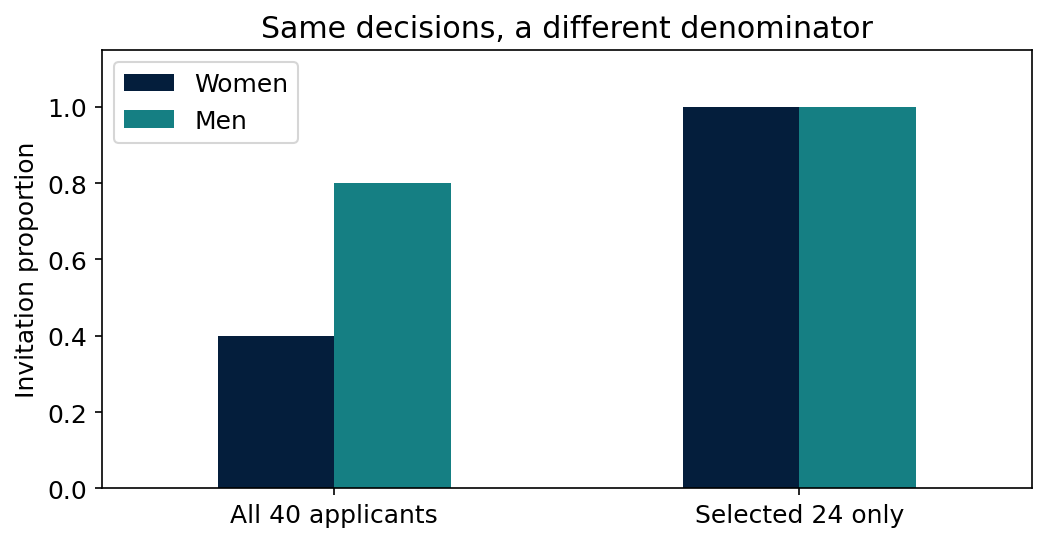

In [6]:
comparison = pd.DataFrame({'Women': [.4, 1.0], 'Men': [.8, 1.0]}, index=['All 40 applicants', 'Selected 24 only'])  # Preserve the two different report populations.
fig, ax = plt.subplots(figsize=(8, 3.8))  # Create a side-by-side rate comparison.
comparison.plot.bar(ax=ax, color=['#041E3C', '#157F83'], rot=0)  # Compare full and conditional rates without claiming an intervention.
ax.set(ylim=(0, 1.15), ylabel='Invitation proportion', title='Same decisions, a different denominator')  # Label what changed.
plt.show()  # Display the selection-bias example.
excluded.to_csv(root / 'data/processed/excluded_applicants.csv', index=False)  # Save the IDs required to investigate the sample boundary.

### 5. A legitimate restriction needs a defensible purpose
Not all filtering is unethical. A report can have a justified scope, such as one complete application per person or a relevant, accessible eligibility criterion. State that scope, record exclusions and explain whom the conclusion covers.

A report of “invitation rates among car owners” can honestly describe that conditional population. It cannot stand in for “fair access among all complete applicants.” In this case the analyst conceals that distinction.

Deleting `group` from the decision formula changes nothing: the formula already omitted it. The car feature, its claimed meaning and the reporting filter require review. In a real audit, collect and protect demographic information appropriately rather than inferring identities just to populate a fairness table.

In [7]:
checks = pd.DataFrame({'check': ['All raw applications complete', 'All meet stated cutoff', 'No unexplained record loss', 'Original decisions preserved'], 'passed': [raw.application_complete.eq(1).all(), raw.skill_score.ge(70).all(), len(published)+len(excluded)==len(raw), 'invited' in engineered.columns]})  # Translate scenario assumptions into inspectable data checks.
print(checks.to_string(index=False))  # Read checks alongside a substantive explanation of relevance.
assert checks.passed.all()  # Verify bookkeeping, while remembering that bookkeeping does not prove ethical validity.

                        check  passed
All raw applications complete    True
       All meet stated cutoff    True
   No unexplained record loss    True
 Original decisions preserved    True


### 6. Change the investigated rule and preserve the original
For the stated online assessment, remove the unnecessary car criterion and invite all applicants meeting the skill cutoff, subject to the stated 40 seats. Store a separate revised output. It invites 20/20 women and 20/20 men. Sixteen people gain access.

This is a rerun of an explicit policy on the same constructed inputs, not an estimated real-world causal effect. A result of equal assessment access does not establish fairness of the skill test, later interviews, job offers, other groups or future cohorts.

In [8]:
engineered['invited_revised'] = engineered.meets_minimum  # Apply the reviewed criterion in this forty-seat scenario.
engineered['denied_revised'] = 1-engineered.invited_revised  # Keep a separate adverse outcome for comparison.
changed = engineered.loc[engineered.invited.ne(engineered.invited_revised)].copy()  # Identify who actually gains access.
print(report(engineered, 'invited_revised').to_string(index=False))  # Report the new rule on the same full population.
print('Changed decisions:', len(changed), changed.group.value_counts().to_dict())  # Connect a metric change to people.
assert len(changed) == 16 and engineered.invited_revised.sum() == 40  # Check the worked intervention arithmetic.
assert engineered.invited.sum() == 24  # Confirm the original output was not overwritten.
engineered.to_csv(root / 'data/processed/reviewed_policy_outputs.csv', index=False)  # Preserve both versions for inspection.

group  events  total  rate
Women      20     20   1.0
  Men      20     20   1.0
Changed decisions: 16 {'Women': 12, 'Men': 4}


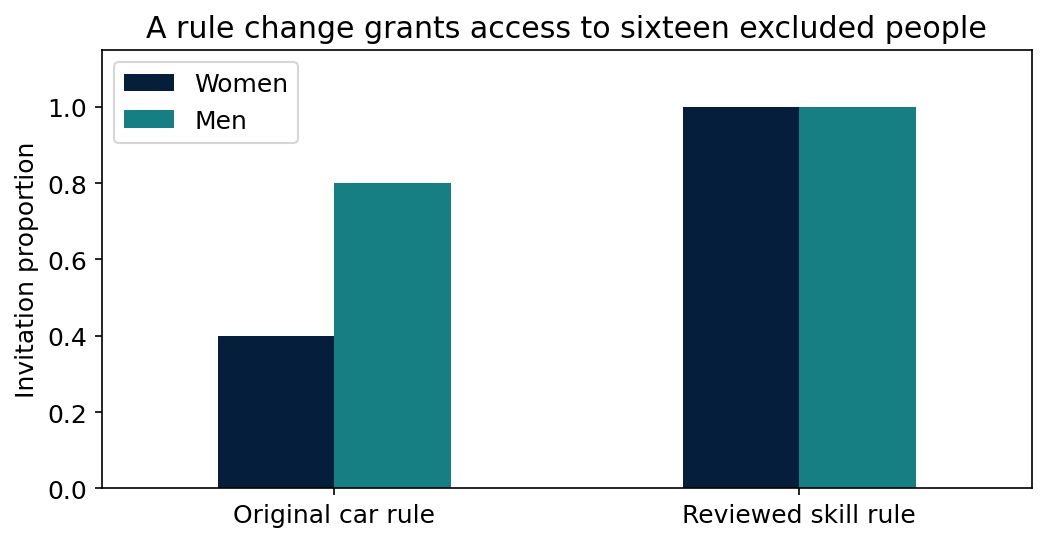

In [9]:
policy_rates = pd.DataFrame({'Women': [.4, 1.0], 'Men': [.8, 1.0]}, index=['Original car rule', 'Reviewed skill rule'])  # Compare two policies on the same full cohort.
fig, ax = plt.subplots(figsize=(8, 3.8))  # Create an actual before/after policy figure.
policy_rates.plot.bar(ax=ax, color=['#041E3C', '#157F83'], rot=0)  # Visualize the revised access decisions.
ax.set(ylim=(0, 1.15), ylabel='Invitation proportion', title='A rule change grants access to sixteen excluded people')  # State the concrete intervention consequence.
plt.show()  # Display the evaluated remedy.

### 7. Required classroom memo
In a short paragraph or a one-page audit record, state:

1. The benefit, population, capacity and minimum criterion.
2. The two lines of feature/policy code that create the burden.
3. The full and selected denominators, and the 16 excluded IDs.
4. Why the published zero gap describes a selected sample rather than an improvement.
5. The separate revised output, who gains access, and one unresolved ethical question.

Do not infer real intent from group counts. Do not generalize this constructed car distribution to women or men in a real population.

# Part 2 — Guided final-project extensions
Choose one path and preserve a clear question, versioned raw/processed data, a record-selection log and interpretable outcomes. Submit an executed notebook and a decision memo. Complex algorithms are optional; a defensible process explanation is required.

## TODO A — Feature alternatives and construct validity
Replace car ownership with a directly relevant measure, such as availability for a clearly specified required activity. Explain how that measure would be collected, what it really measures, accessibility and accommodation, possible proxies and remaining uncertainty. Compare actual access decisions, not only feature correlations.

In [10]:
feature_review = {'proposed_feature': None, 'claimed_construct': None, 'job_relevance': None, 'collection_method': None, 'accessibility_risks': None}  # Declare an ethical feature-review scaffold.
print(feature_review)  # TODO: justify one alternative before implementing it.

{'proposed_feature': None, 'claimed_construct': None, 'job_relevance': None, 'collection_method': None, 'accessibility_risks': None}


## TODO B — A genuinely limited-capacity extension
Change capacity from 40 to 12. “Invite everyone” is no longer feasible. Define and justify a process among eligible applicants, such as a relevant score rule or transparent lottery with appeal/accommodation. Predeclare tie handling and compare access, error/utility measures only when their reference meanings are valid, and subgroup burdens. Do not claim that exact group parity alone settles the normative choice.

## TODO C — Reporting selection and intention
Create two pipelines yielding the same biased sample: one accidental join/filter error and one deliberately misleading definition. Explain what extra evidence distinguishes their intent, what harms are shared and what different accountability responses might be appropriate. Publish the full exclusion flow and corrected report.

## TODO D — A fresh-cohort follow-up
Create new constructed records with a declared generator and different seed. Freeze the feature definitions, eligibility rule and reporting scope before seeing outcomes. Evaluate the reviewed process on that cohort. Assess which assumptions travel and which do not. Do not retune a policy on the same records and call that independent confirmation.

## TODO E — Self-study and oral check
Read Suresh & Guttag's sources-of-harm framework and connect measurement, representation and evaluation bias to exact lines in this example. Explain why a confidence interval cannot repair a systematically selected reporting population. In an oral check, trace one excluded ID and recompute one denominator without a helper.

Full references are in `SOURCES.md`. The raw data are constructed for this course, not taken from an employer.